In [21]:
# Mount google drive
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [22]:
# Import the libraries required for data preparation, transfer learning, and evaluation.
import os
import shutil
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import glob

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score
)

print("TensorFlow version:", tf.__version__)
print("Available GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
Available GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [23]:
# Define project paths and copy the dataset to Colab local storage if needed.
PROJECT_DIR = '/content/drive/MyDrive/Brain_Tumor_CNN_Project'
DRIVE_DATASET_DIR = os.path.join(PROJECT_DIR, 'dataset', 'Epic and CSCR hospital Dataset')
LOCAL_DATASET_DIR = '/content/brain_tumor_dataset'
MODEL_DIR = os.path.join(PROJECT_DIR, 'models')
RESULTS_DIR = os.path.join(PROJECT_DIR, 'results', 'convnext')
os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

if not os.path.isdir(os.path.join(LOCAL_DATASET_DIR, 'Train')) or not os.path.isdir(os.path.join(LOCAL_DATASET_DIR, 'Test')):
    if not os.path.isdir(DRIVE_DATASET_DIR):
        raise FileNotFoundError(f'Dataset folder not found: {DRIVE_DATASET_DIR}. Check your Drive folder structure.')
    if os.path.exists(LOCAL_DATASET_DIR):
        shutil.rmtree(LOCAL_DATASET_DIR)
    shutil.copytree(DRIVE_DATASET_DIR, LOCAL_DATASET_DIR)

TRAIN_DIR = os.path.join(LOCAL_DATASET_DIR, 'Train')
TEST_DIR = os.path.join(LOCAL_DATASET_DIR, 'Test')
print('Dataset:', LOCAL_DATASET_DIR)
print('Train exists:', os.path.isdir(TRAIN_DIR), '| Test exists:', os.path.isdir(TEST_DIR))

Dataset: /content/brain_tumor_dataset
Train exists: True | Test exists: True


In [24]:
# Collect sorted image paths and map the four source folders into binary labels.
CLASS_MAPPING = {'notumor': 0, 'glioma': 1, 'meningioma': 1, 'pituitary': 1}
IMAGE_EXTENSIONS = ('.jpg', '.jpeg', '.png', '.bmp', '.jfif')

def collect_images(split_dir):
    records = []
    for source_class in sorted(os.listdir(split_dir)):
        class_dir = os.path.join(split_dir, source_class)
        if not os.path.isdir(class_dir) or source_class.lower() not in CLASS_MAPPING:
            continue
        for image_path in sorted(glob.glob(os.path.join(class_dir, '**', '*'), recursive=True)):
            if os.path.isfile(image_path) and image_path.lower().endswith(IMAGE_EXTENSIONS):
                records.append({'image_path': image_path, 'original_class': source_class.lower(),
                                'label': CLASS_MAPPING[source_class.lower()]})
    return pd.DataFrame(records).sort_values(['original_class', 'image_path']).reset_index(drop=True)

all_train_df = collect_images(TRAIN_DIR)
test_df = collect_images(TEST_DIR)
if all_train_df.empty or test_df.empty:
    raise ValueError('No images found. Verify that Train/Test contain glioma, meningioma, notumor and pituitary folders.')
print('Train images:', len(all_train_df), '| Test images:', len(test_df))
print('Training counts by source class:', all_train_df['original_class'].value_counts().sort_index())
print('Test counts by source class:', test_df['original_class'].value_counts().sort_index())
print('Binary train counts:', all_train_df['label'].map({0:'Non-Tumourous', 1:'Tumourous'}).value_counts())

Train images: 9650 | Test images: 2415
Training counts by source class: original_class
glioma        3018
meningioma    2183
notumor       1945
pituitary     2504
Name: count, dtype: int64
Test counts by source class: original_class
glioma        756
meningioma    546
notumor       487
pituitary     626
Name: count, dtype: int64
Binary train counts: label
Tumourous        7705
Non-Tumourous    1945
Name: count, dtype: int64


In [25]:
# Create a stratified validation split and save the exact manifests for reproducibility.
train_df, val_df = train_test_split(all_train_df, test_size=0.20, random_state=42,
                                    stratify=all_train_df['label'])
train_df = train_df.sort_values('image_path').reset_index(drop=True)
val_df = val_df.sort_values('image_path').reset_index(drop=True)
test_df = test_df.sort_values('image_path').reset_index(drop=True)
train_df.to_csv(os.path.join(RESULTS_DIR, 'train_manifest.csv'), index=False)
val_df.to_csv(os.path.join(RESULTS_DIR, 'validation_manifest.csv'), index=False)
test_df.to_csv(os.path.join(RESULTS_DIR, 'test_manifest.csv'), index=False)
print(f'Train={len(train_df)}, Validation={len(val_df)}, Test={len(test_df)}')

Train=7720, Validation=1930, Test=2415


In [7]:
# Build image pipelines; ConvNeXt's Keras preprocessing expects float pixel values in the 0–255 range.
IMG_SIZE = (224, 224)
BATCH_SIZE = 16  # If GPU memory is limited, reduce to 8.
AUTOTUNE = tf.data.AUTOTUNE

def decode_resize(path, label):
    image_bytes = tf.io.read_file(path)
    image = tf.io.decode_image(image_bytes, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE, antialias=True)
    image = tf.cast(image, tf.float32)  # Keep 0–255; ConvNeXt includes preprocessing by default.
    return image, tf.cast(label, tf.float32)

def make_dataset(frame, training=False):
    ds = tf.data.Dataset.from_tensor_slices((frame['image_path'].values, frame['label'].values.astype('float32')))
    if training:
        ds = ds.shuffle(len(frame), seed=42, reshuffle_each_iteration=True)
    ds = ds.map(decode_resize, num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)
for batch_images, batch_labels in train_ds.take(1):
    print('Image batch:', batch_images.shape, '| dtype:', batch_images.dtype,
          '| range:', float(tf.reduce_min(batch_images)), 'to', float(tf.reduce_max(batch_images)))
    print('Label batch:', batch_labels.shape)

Image batch: (16, 224, 224, 3) | dtype: <dtype: 'float32'> | range: 0.0 to 255.0
Label batch: (16,)


In [8]:
# Define focal loss and a model factory so both experiments use the same architecture.
FOCAL_GAMMA = 2.0
FOCAL_ALPHA = 0.25

def binary_focal_loss(gamma=FOCAL_GAMMA, alpha=FOCAL_ALPHA):
    def loss(y_true, y_pred):
        y_true = tf.cast(tf.reshape(y_true, [-1, 1]), tf.float32)
        y_pred = tf.clip_by_value(tf.cast(y_pred, tf.float32), tf.keras.backend.epsilon(), 1.0 - tf.keras.backend.epsilon())
        p_t = y_true * y_pred + (1.0 - y_true) * (1.0 - y_pred)
        alpha_t = y_true * alpha + (1.0 - y_true) * (1.0 - alpha)
        return tf.reduce_mean(-alpha_t * tf.pow(1.0 - p_t, gamma) * tf.math.log(p_t))
    loss.__name__ = 'binary_focal_loss'
    return loss

def build_convnext_model():
    # Use ImageNet pretrained ConvNeXt-Tiny features and replace the original classification head.
    backbone = tf.keras.applications.ConvNeXtTiny(include_top=False, weights='imagenet',
                                                   input_shape=(224, 224, 3), pooling='avg')
    backbone.trainable = False
    inputs = tf.keras.Input(shape=(224, 224, 3), name='mri_image')
    x = backbone(inputs, training=False)
    x = tf.keras.layers.LayerNormalization(epsilon=1e-6)(x)
    x = tf.keras.layers.Dropout(0.30)(x)
    outputs = tf.keras.layers.Dense(1, activation='sigmoid', name='tumour_probability')(x)
    model = tf.keras.Model(inputs, outputs, name='ConvNeXtTiny_BinaryMRI')
    return model, backbone

print('ConvNeXtTiny available:', hasattr(tf.keras.applications, 'ConvNeXtTiny'))

ConvNeXtTiny available: True


In [9]:
# Define callbacks, including checkpointing, early stopping, and learning-rate scheduling.
def make_callbacks(run_name):
    checkpoint_path = os.path.join(MODEL_DIR, f'best_convnext_{run_name}.weights.h5')
    return [
        tf.keras.callbacks.ModelCheckpoint(checkpoint_path, monitor='val_loss', mode='min',
                                           save_best_only=True, save_weights_only=True, verbose=1),
        tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True, verbose=1),
        tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=2,
                                             min_lr=1e-7, verbose=1)
    ], checkpoint_path

EPOCHS_HEAD = 5
EPOCHS_FINE_TUNE = 8
INITIAL_LR = 1e-3
FINE_TUNE_LR = 1e-5
FINE_TUNE_LAST_LAYERS = 30
print('Configuration:', {'batch_size': BATCH_SIZE, 'head_epochs': EPOCHS_HEAD,
                         'fine_tune_epochs': EPOCHS_FINE_TUNE, 'initial_lr': INITIAL_LR,
                         'fine_tune_lr': FINE_TUNE_LR})

Configuration: {'batch_size': 16, 'head_epochs': 5, 'fine_tune_epochs': 8, 'initial_lr': 0.001, 'fine_tune_lr': 1e-05}


In [10]:
# Train one ConvNeXt experiment in two stages and return validation/test predictions and histories.
def train_experiment(run_name, loss_name='bce'):
    tf.keras.backend.clear_session()
    model, backbone = build_convnext_model()
    loss_fn = 'binary_crossentropy' if loss_name == 'bce' else binary_focal_loss()
    model.compile(optimizer=tf.keras.optimizers.Adam(INITIAL_LR), loss=loss_fn,
                  metrics=[tf.keras.metrics.BinaryAccuracy(name='accuracy'),
                           tf.keras.metrics.Precision(name='precision'),
                           tf.keras.metrics.Recall(name='recall'),
                           tf.keras.metrics.AUC(name='roc_auc'),
                           tf.keras.metrics.AUC(name='pr_auc', curve='PR')])
    callbacks, checkpoint_path = make_callbacks(run_name)
    print(f'\n===== {run_name}: frozen-backbone training =====')
    hist_head = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_HEAD, callbacks=callbacks, verbose=1)

    # Fine-tune only the final portion of the backbone; keep normalization layers frozen for stability.
    backbone.trainable = True
    for layer in backbone.layers[:-FINE_TUNE_LAST_LAYERS]:
        layer.trainable = False
    for layer in backbone.layers:
        if isinstance(layer, tf.keras.layers.LayerNormalization):
            layer.trainable = False
    model.compile(optimizer=tf.keras.optimizers.Adam(FINE_TUNE_LR), loss=loss_fn,
                  metrics=[tf.keras.metrics.BinaryAccuracy(name='accuracy'),
                           tf.keras.metrics.Precision(name='precision'),
                           tf.keras.metrics.Recall(name='recall'),
                           tf.keras.metrics.AUC(name='roc_auc'),
                           tf.keras.metrics.AUC(name='pr_auc', curve='PR')])
    callbacks_ft, checkpoint_path = make_callbacks(run_name)
    print(f'\n===== {run_name}: fine-tuning =====')
    hist_ft = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_FINE_TUNE,
                        callbacks=callbacks_ft, verbose=1)
    model.load_weights(checkpoint_path)
    model_path = os.path.join(MODEL_DIR, f'convnext_tiny_{run_name}.keras')
    model.save(model_path, include_optimizer=False)

    y_true = test_df['label'].to_numpy().astype(int)
    y_prob = model.predict(test_ds, verbose=1).ravel()
    y_pred = (y_prob >= 0.5).astype(int)
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    metrics = {
        'model': f'ConvNeXt-Tiny ({run_name})', 'loss': loss_name,
        'accuracy': accuracy_score(y_true, y_pred),
        'precision_tumour': precision_score(y_true, y_pred, zero_division=0),
        'recall_tumour_sensitivity': recall_score(y_true, y_pred, zero_division=0),
        'f1_tumour': f1_score(y_true, y_pred, zero_division=0),
        'specificity': tn / (tn + fp) if (tn + fp) else 0.0,
        'roc_auc': roc_auc_score(y_true, y_prob) if len(np.unique(y_true)) == 2 else np.nan,
        'pr_auc': average_precision_score(y_true, y_prob) if len(np.unique(y_true)) == 2 else np.nan,
        'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp),
        'model_path': model_path
    }
    pred_df = test_df.copy()
    pred_df['true_label'] = y_true
    pred_df['tumour_probability'] = y_prob
    pred_df['predicted_label'] = y_pred
    pred_df['predicted_class'] = np.where(y_pred == 1, 'Tumourous', 'Non-Tumourous')
    pred_df.to_csv(os.path.join(RESULTS_DIR, f'{run_name}_test_predictions.csv'), index=False)
    pd.DataFrame([metrics]).to_csv(os.path.join(RESULTS_DIR, f'{run_name}_metrics.csv'), index=False)
    with open(os.path.join(RESULTS_DIR, f'{run_name}_classification_report.txt'), 'w') as f:
        f.write(classification_report(y_true, y_pred, target_names=['Non-Tumourous', 'Tumourous'], zero_division=0))
    np.savetxt(os.path.join(RESULTS_DIR, f'{run_name}_confusion_matrix.csv'), cm, delimiter=',', fmt='%d')
    return {'model': model, 'metrics': metrics, 'cm': cm, 'y_true': y_true,
            'y_prob': y_prob, 'y_pred': y_pred, 'hist_head': hist_head.history,
            'hist_ft': hist_ft.history}

print('Training function ready. Each experiment can take a while.')

Training function ready. Each experiment can take a while.


In [11]:
# Train and evaluate both binary-cross-entropy and focal-loss ConvNeXt experiments.
# Set RUN_FOCAL = False if you want to run only the faster BCE baseline first.
RUN_FOCAL = True
results = {}
results['convnext_bce'] = train_experiment('bce', loss_name='bce')
if RUN_FOCAL:
    results['convnext_focal'] = train_experiment('focal', loss_name='focal')

convnext_metrics = pd.DataFrame([item['metrics'] for item in results.values()])
convnext_metrics.to_csv(os.path.join(RESULTS_DIR, 'convnext_experiment_comparison.csv'), index=False)
display(convnext_metrics.drop(columns=['model_path']).style.format(precision=4))

111650432/111650432 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step

===== bce: frozen-backbone training =====
Epoch 1/5
483/483 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step - accuracy: 0.8840 - loss: 0.2952 - pr_auc: 0.9625 - precision: 0.9089 - recall: 0.9504 - roc_auc: 0.8888
Epoch 1: val_loss improved from None to 0.13173, saving model to /content/drive/MyDrive/Brain_Tumor_CNN_Project/models/best_convnext_bce.weights.h5

Epoch 1: finished saving model to /content/drive/MyDrive/Brain_Tumor_CNN_Project/models/best_convnext_bce.weights.h5
483/483 ━━━━━━━━━━━━━━━━━━━━ 88s 142ms/step - accuracy: 0.9260 - loss: 0.1966 - pr_auc: 0.9860 - precision: 0.9399 - recall: 0.9693 - roc_auc: 0.9550 - val_accuracy: 0.9560 - val_loss: 0.1317 - val_pr_auc: 0.9947 - val_precision: 0.9533 - val_recall: 0.9935 - val_roc_auc: 0.9824 - learning_rate: 0.0010
Epoch 2/5
482/483 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - accuracy: 0.9664 - loss: 0.1081 - pr_auc: 0.9957 - precision: 0.9719 - recall: 0.9865 - roc_auc: 0.9841
Epoch 2: val_loss 

,model,loss,accuracy,precision_tumour,recall_tumour_sensitivity,f1_tumour,specificity,roc_auc,pr_auc,tn,fp,fn,tp
0,ConvNeXt-Tiny (bce),bce,0.9909,0.9990,0.9896,0.9943,0.9959,0.9994,0.9999,485,2,20,1908
1,ConvNeXt-Tiny (focal),focal,0.9913,0.9995,0.9896,0.9945,0.9979,0.9996,0.9999,486,1,20,1908



 ConvNeXt-Tiny (bce)
               precision    recall  f1-score   support

Non-Tumourous       0.96      1.00      0.98       487
    Tumourous       1.00      0.99      0.99      1928

     accuracy                           0.99      2415
    macro avg       0.98      0.99      0.99      2415
 weighted avg       0.99      0.99      0.99      2415



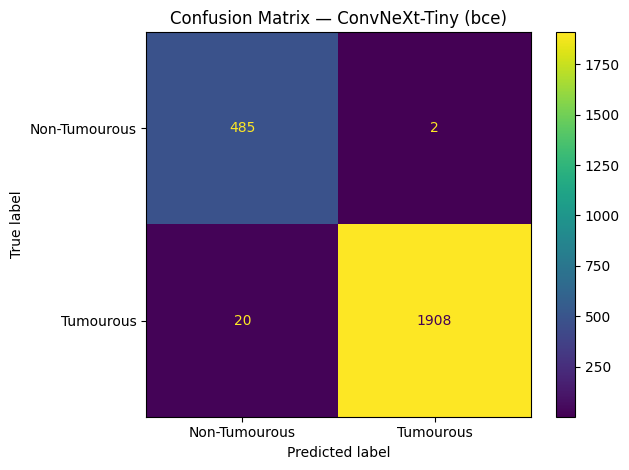


 ConvNeXt-Tiny (focal)
               precision    recall  f1-score   support

Non-Tumourous       0.96      1.00      0.98       487
    Tumourous       1.00      0.99      0.99      1928

     accuracy                           0.99      2415
    macro avg       0.98      0.99      0.99      2415
 weighted avg       0.99      0.99      0.99      2415



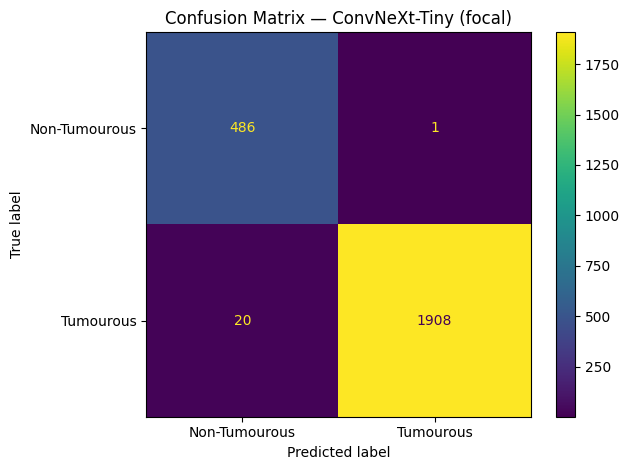

In [28]:
# Plot confusion matrices and summarize each experiment's classification report.
for run_name, item in results.items():
    print('\n', item['metrics']['model'])
    print(classification_report(item['y_true'], item['y_pred'],
                                target_names=['Non-Tumourous', 'Tumourous'], zero_division=0))
    disp = ConfusionMatrixDisplay(item['cm'], display_labels=['Non-Tumourous', 'Tumourous'])
    disp.plot(values_format='d')
    plt.title(f"Confusion Matrix — {item['metrics']['model']}")
    plt.tight_layout()
    plt.show()

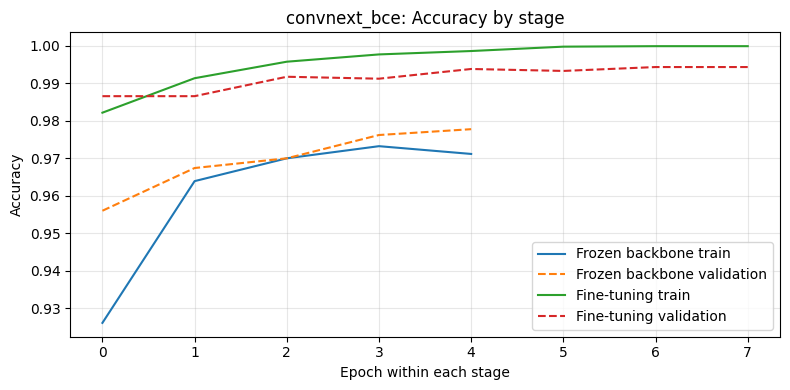

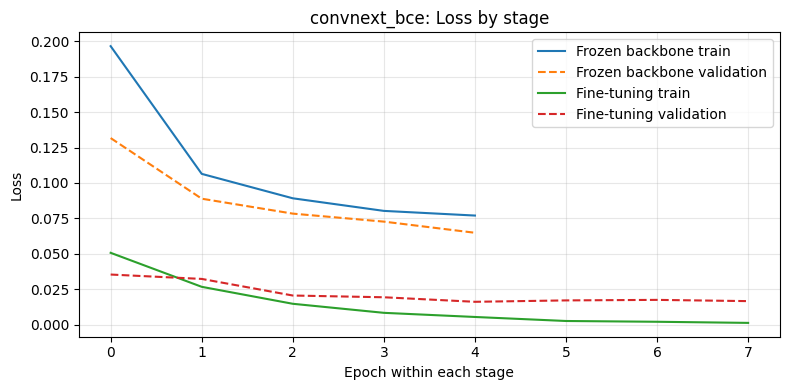

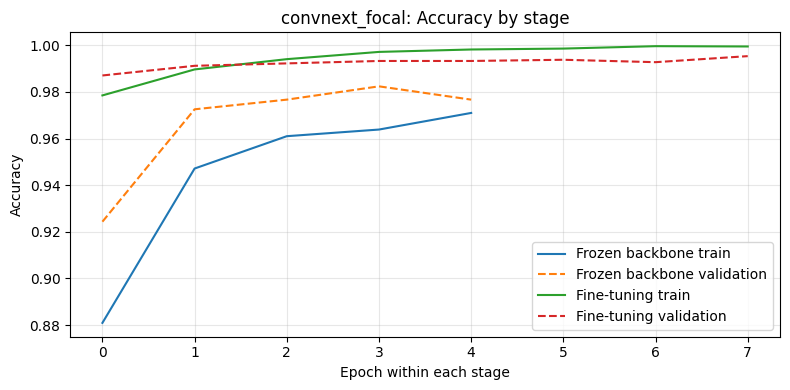

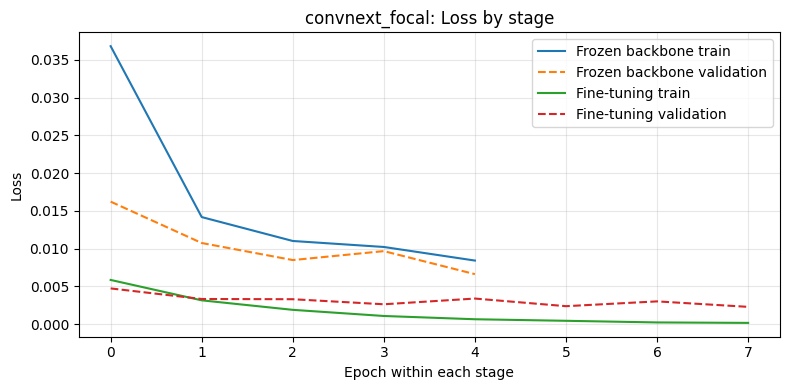

In [29]:
# Plot training and validation accuracy/loss for the head-training and fine-tuning stages.
for run_name, item in results.items():
    for metric_name in ['accuracy', 'loss']:
        plt.figure(figsize=(8, 4))
        for stage_name, history in [('Frozen backbone', item['hist_head']), ('Fine-tuning', item['hist_ft'])]:
            if metric_name in history:
                plt.plot(history[metric_name], label=f'{stage_name} train')
            val_key = 'val_' + metric_name
            if val_key in history:
                plt.plot(history[val_key], linestyle='--', label=f'{stage_name} validation')
        plt.title(f'{run_name}: {metric_name.title()} by stage')
        plt.xlabel('Epoch within each stage')
        plt.ylabel(metric_name.title())
        plt.legend()
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.savefig(os.path.join(RESULTS_DIR, f'{run_name}_{metric_name}_curves.png'), dpi=150)
        plt.show()

In [30]:
# Compare ConvNeXt with the historical custom-CNN result and any saved EfficientNet metrics.
# Previously reported custom CNN test accuracy was 96.89%; tumour precision 99.89%, recall 96.21%, F1 98.02%.
comparison_rows = [
    {'model': 'Custom CNN (previous run)', 'accuracy': 0.9689,
     'precision_tumour': 0.9989, 'recall_tumour_sensitivity': 0.9621, 'f1_tumour': 0.9802,
     'specificity': np.nan, 'roc_auc': np.nan, 'pr_auc': np.nan,
     'tn': 485, 'fp': 2, 'fn': 73, 'tp': 1854}
]
for _, row in convnext_metrics.iterrows():
    comparison_rows.append(row.to_dict())

# Try to locate a saved EfficientNet metrics CSV; only files with recognizable metric columns are used.
efficientnet_csvs = glob.glob(os.path.join(PROJECT_DIR, 'results', '**', '*.csv'), recursive=True)
efficientnet_loaded = False
for csv_path in sorted(efficientnet_csvs):
    if 'convnext' in csv_path.lower() or 'prediction' in os.path.basename(csv_path).lower() or 'manifest' in os.path.basename(csv_path).lower():
        continue
    try:
        candidate = pd.read_csv(csv_path)
        cols = {c.lower(): c for c in candidate.columns}
        acc_col = next((cols[c] for c in cols if c in ['accuracy', 'test_accuracy']), None)
        if acc_col and any('efficientnet' in str(x).lower() for x in candidate.astype(str).values.flatten()[:100]):
            comparison_rows.append({'model': f'EfficientNet result from {os.path.basename(csv_path)}',
                                    'accuracy': float(candidate[acc_col].iloc[0])})
            efficientnet_loaded = True
            break
    except Exception:
        pass

comparison_df = pd.DataFrame(comparison_rows)
comparison_df.to_csv(os.path.join(RESULTS_DIR, 'all_model_comparison.csv'), index=False)
display(comparison_df.style.format(precision=4, na_rep='—'))
if not efficientnet_loaded:
    print('No compatible EfficientNet metrics CSV was auto-detected. Add the actual EfficientNet test metrics to comparison_rows before drawing a final ranking.')

,model,accuracy,precision_tumour,recall_tumour_sensitivity,f1_tumour,specificity,roc_auc,pr_auc,tn,fp,fn,tp,loss,model_path
0,Custom CNN (previous run),0.9689,0.9989,0.9621,0.9802,—,—,—,485,2,73,1854,—,—
1,ConvNeXt-Tiny (bce),0.9909,0.9990,0.9896,0.9943,0.9959,0.9994,0.9999,485,2,20,1908,bce,/content/drive/MyDrive/Brain_Tumor_CNN_Project/models/convnext_tiny_bce.keras
2,ConvNeXt-Tiny (focal),0.9913,0.9995,0.9896,0.9945,0.9979,0.9996,0.9999,486,1,20,1908,focal,/content/drive/MyDrive/Brain_Tumor_CNN_Project/models/convnext_tiny_focal.keras


No compatible EfficientNet metrics CSV was auto-detected. Add the actual EfficientNet test metrics to comparison_rows before drawing a final ranking.


In [33]:
# Review false negatives and false positives for each ConvNeXt experiment.
for run_name, item in results.items():
    pred = pd.read_csv(os.path.join(RESULTS_DIR, f'bce_test_predictions.csv'))
    false_negatives = pred[(pred['true_label'] == 1) & (pred['predicted_label'] == 0)]
    false_positives = pred[(pred['true_label'] == 0) & (pred['predicted_label'] == 1)]
    print(f'\n{run_name}: false negatives={len(false_negatives)}, false positives={len(false_positives)}')
    display(false_negatives[['image_path', 'original_class', 'tumour_probability']].head(10))
    display(false_positives[['image_path', 'original_class', 'tumour_probability']].head(10))


convnext_bce: false negatives=20, false positives=2


,image_path,original_class,tumour_probability
469,/content/brain_tumor_dataset/Test/glioma/G_682...,glioma,0.451429
509,/content/brain_tumor_dataset/Test/glioma/G_688...,glioma,0.400318
517,/content/brain_tumor_dataset/Test/glioma/G_689...,glioma,0.415102
529,/content/brain_tumor_dataset/Test/glioma/G_690...,glioma,0.030237
530,/content/brain_tumor_dataset/Test/glioma/G_690...,glioma,0.005886
531,/content/brain_tumor_dataset/Test/glioma/G_690...,glioma,0.002064
532,/content/brain_tumor_dataset/Test/glioma/G_690...,glioma,0.007209
533,/content/brain_tumor_dataset/Test/glioma/G_690...,glioma,0.000932
534,/content/brain_tumor_dataset/Test/glioma/G_690...,glioma,0.000368
620,/content/brain_tumor_dataset/Test/glioma/G_701...,glioma,0.097873


,image_path,original_class,tumour_probability
1425,/content/brain_tumor_dataset/Test/notumor/1232...,notumor,0.664243
1782,/content/brain_tumor_dataset/Test/notumor/43 n...,notumor,0.943781



convnext_focal: false negatives=20, false positives=2


,image_path,original_class,tumour_probability
469,/content/brain_tumor_dataset/Test/glioma/G_682...,glioma,0.451429
509,/content/brain_tumor_dataset/Test/glioma/G_688...,glioma,0.400318
517,/content/brain_tumor_dataset/Test/glioma/G_689...,glioma,0.415102
529,/content/brain_tumor_dataset/Test/glioma/G_690...,glioma,0.030237
530,/content/brain_tumor_dataset/Test/glioma/G_690...,glioma,0.005886
531,/content/brain_tumor_dataset/Test/glioma/G_690...,glioma,0.002064
532,/content/brain_tumor_dataset/Test/glioma/G_690...,glioma,0.007209
533,/content/brain_tumor_dataset/Test/glioma/G_690...,glioma,0.000932
534,/content/brain_tumor_dataset/Test/glioma/G_690...,glioma,0.000368
620,/content/brain_tumor_dataset/Test/glioma/G_701...,glioma,0.097873


,image_path,original_class,tumour_probability
1425,/content/brain_tumor_dataset/Test/notumor/1232...,notumor,0.664243
1782,/content/brain_tumor_dataset/Test/notumor/43 n...,notumor,0.943781


In [34]:
# Save an experiment summary and list the output artifacts for later reporting.
import json

summary = {
    'architecture': 'ConvNeXt-Tiny',
    'image_size': list(IMG_SIZE),
    'seed': 42,
    'batch_size': BATCH_SIZE,
    'epochs_head_max': EPOCHS_HEAD,
    'epochs_fine_tune_max': EPOCHS_FINE_TUNE,
    'focal_gamma': FOCAL_GAMMA,
    'focal_alpha': FOCAL_ALPHA,
    'train_count': int(len(train_df)),
    'validation_count': int(len(val_df)),
    'test_count': int(len(test_df)),
    'results': [item['metrics'] for item in results.values()]
}
with open(os.path.join(RESULTS_DIR, 'experiment_summary.json'), 'w') as f:
    json.dump(summary, f, indent=2)
print('Saved results to:', RESULTS_DIR)
for path in sorted(glob.glob(os.path.join(RESULTS_DIR, '*'))):
    print(os.path.basename(path))

Saved results to: /content/drive/MyDrive/Brain_Tumor_CNN_Project/results/convnext
all_model_comparison.csv
bce_classification_report.txt
bce_confusion_matrix.csv
bce_metrics.csv
bce_test_predictions.csv
convnext_bce_accuracy_curves.png
convnext_bce_loss_curves.png
convnext_experiment_comparison.csv
convnext_focal_accuracy_curves.png
convnext_focal_loss_curves.png
experiment_summary.json
focal_classification_report.txt
focal_confusion_matrix.csv
focal_metrics.csv
focal_test_predictions.csv
test_accuracy_comparison.png
test_manifest.csv
test_metrics_comparison.png
train_manifest.csv
validation_manifest.csv
